In [60]:
import pandas as pd
import numpy as np
from plotnine import *

In [61]:
data = pd.read_csv('labeled.csv')
data.head()

,id,president,year,title,speech_type,word_count,text,llm_label,llm_reason,model
0,0,Abraham Lincoln,1852,"July 6, 1852: Eulogy on Henry Clay",Other,10814,Honors To Henry Clay On the fourth day of Jul...,welcoming,The text praises Henry Clay's support for the ...,gemini-3.5-flash-lite
1,1,Abraham Lincoln,1854,"October 16, 1854: At Peoria, Illinois",Other,33240,"The repeal of the Missouri Compromise, and the...",restrictive,The text argues strongly against the repeal of...,gemini-3.5-flash-lite
2,2,Abraham Lincoln,1858,"June 16, 1858: ""A House Divided"" Speech",Address / Speech,3224,Mr. PRESIDENT and Gentlemen of the Convention....,not relevant,The text discusses historical political debate...,gemini-3.5-flash-lite
3,3,Abraham Lincoln,1860,"February 27, 1860: Cooper Union Address",Address / Speech,13719,Mr. President and fellow citizens of New York:...,not relevant,"The text discusses slavery, constitutional int...",gemini-3.5-flash-lite
4,4,Abraham Lincoln,1861,"February 11, 1861: Farewell Address",Farewell Address,152,"My friends---No one, not in my situation, can ...",not relevant,The text is a farewell speech to friends and c...,gemini-3.5-flash-lite


In [62]:
data['llm_label'].value_counts(normalize=True)

llm_label
not relevant    0.800755
restrictive     0.095373
welcoming       0.080264
neutral         0.023607
Name: proportion, dtype: float64

In [63]:
data['speech_type'][data['llm_label'] == 'welcoming'].value_counts()

speech_type
State of the Union     32
Address / Speech       16
Remarks / Statement     8
Message                 6
Inaugural Address       5
Farewell Address        5
Other                   3
Convention Speech       3
Veto Message            3
Press Conference        3
Debate                  1
Name: count, dtype: int64

In [64]:
data['president'][data['llm_label'] == 'welcoming'].value_counts()

president
Barack Obama            20
Joe Biden                9
Ronald Reagan            7
Abraham Lincoln          5
Lyndon B. Johnson        5
Bill Clinton             4
Dwight D. Eisenhower     4
George W. Bush           4
John Tyler               4
William McKinley         2
Ulysses S. Grant         2
Theodore Roosevelt       2
James K. Polk            2
Grover Cleveland         2
Chester A. Arthur        2
Woodrow Wilson           2
Andrew Johnson           1
John F. Kennedy          1
James Buchanan           1
Millard Fillmore         1
Gerald Ford              1
Rutherford B. Hayes      1
George H. W. Bush        1
Thomas Jefferson         1
Franklin Pierce          1
Name: count, dtype: int64

In [65]:
(data.loc[data['llm_label'] == 'welcoming', 'year'] // 10 * 10).value_counts().sort_index()

year
1800     1
1840     6
1850     4
1860     5
1870     2
1880     4
1890     3
1900     2
1910     2
1950     4
1960     6
1970     1
1980     8
1990     3
2000     6
2010    19
2020     9
Name: count, dtype: int64

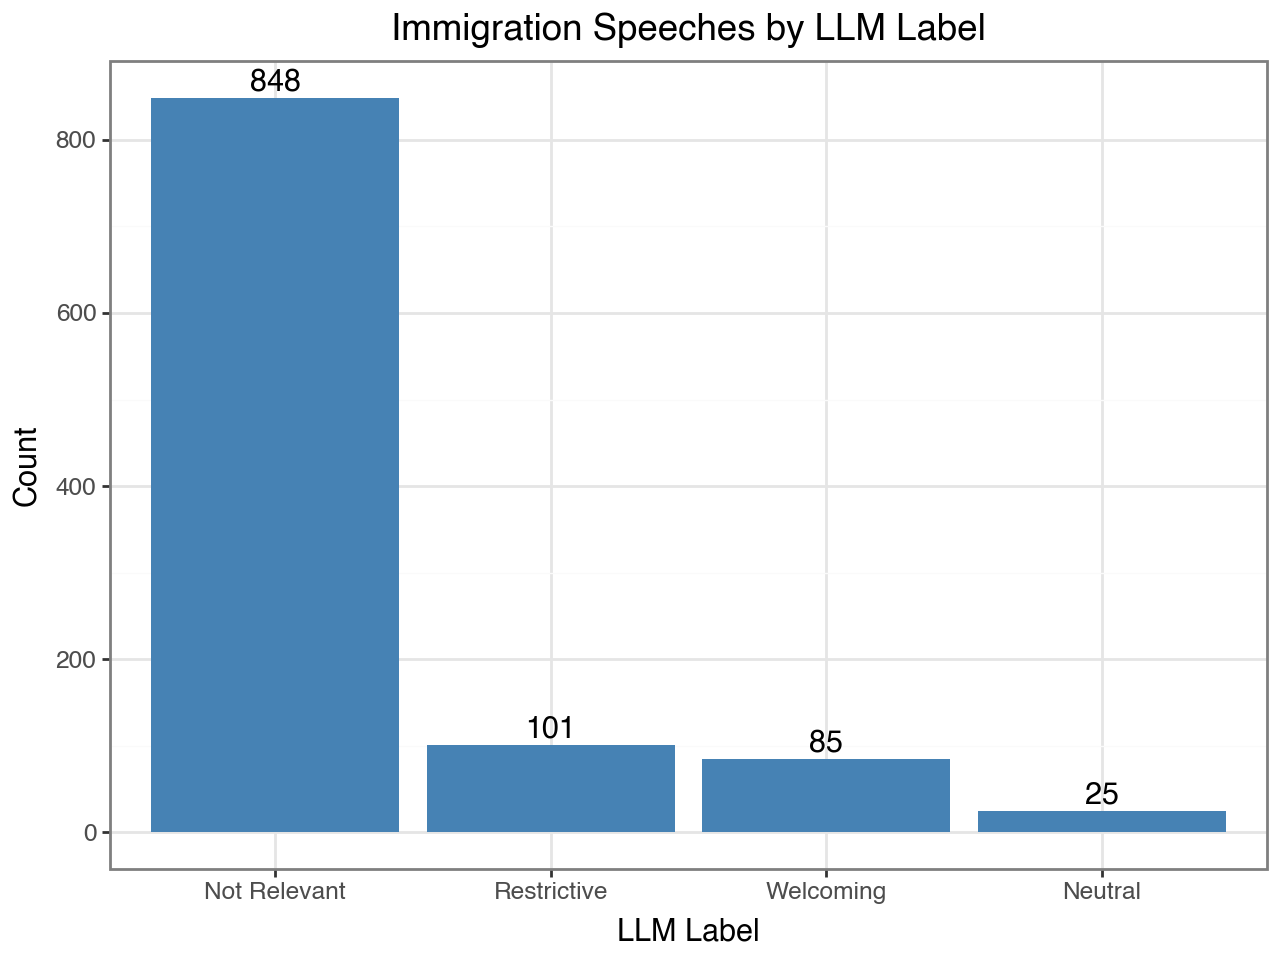

In [94]:
(
    ggplot(data, aes('llm_label')) +
    geom_bar(fill = 'steelblue') +
    scale_x_discrete(limits = ['not relevant', 'restrictive', 'welcoming', 'neutral'], labels = {
        'neutral': 'Neutral',
        'not relevant': 'Not Relevant',
        'restrictive': 'Restrictive',
        'welcoming': 'Welcoming'
    }) +
    geom_text(
        aes(label=after_stat("count")),
        stat="count",
        va="bottom",
        nudge_y=0.5,
    ) +
    labs(title = 'Immigration Speeches by LLM Label', x = 'LLM Label', y = 'Count') +
    theme_bw()
)

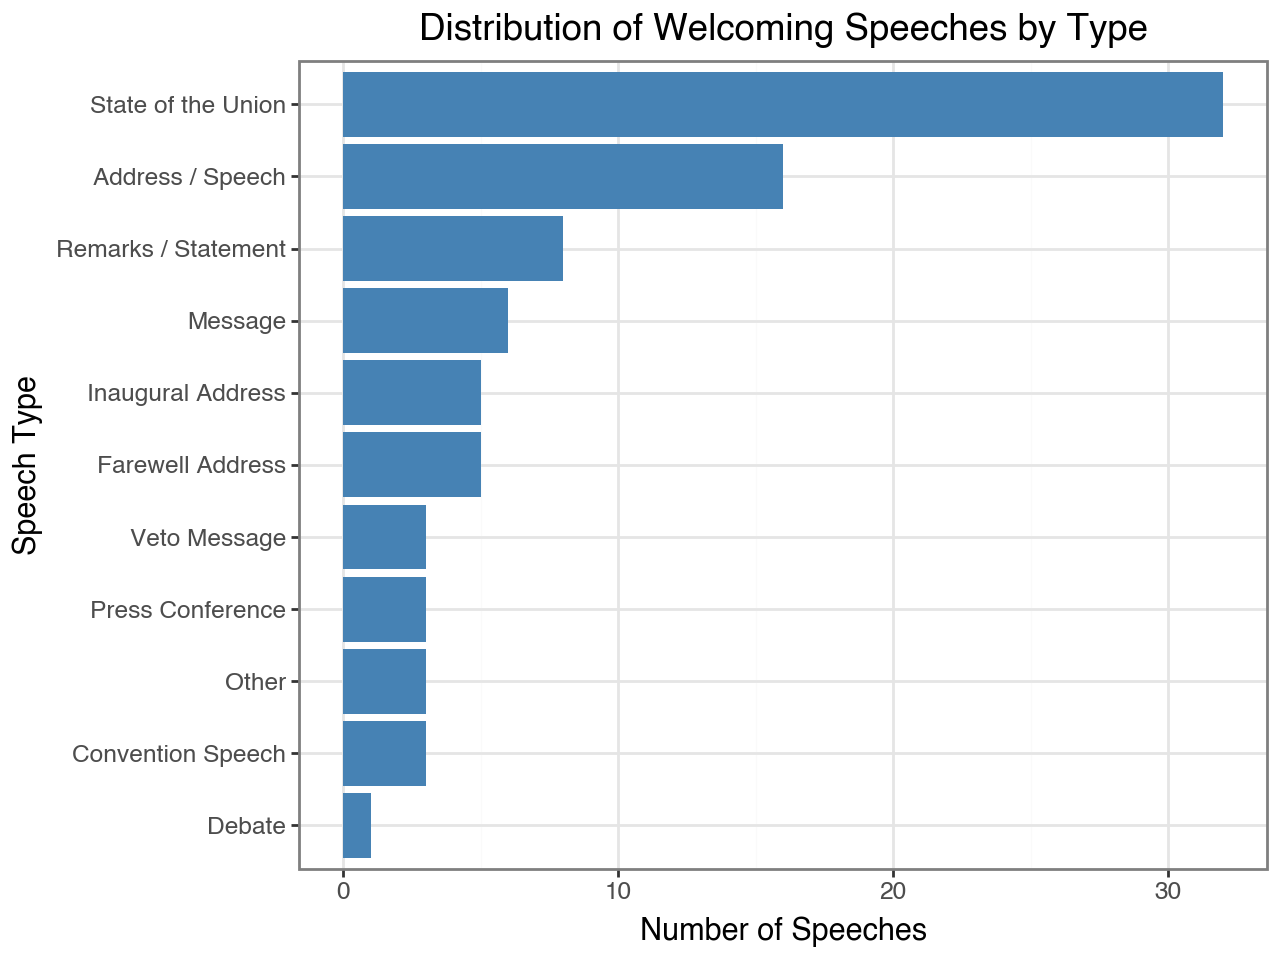

In [120]:
(
    ggplot(data[data['llm_label'] == 'welcoming']['speech_type']
        .value_counts()
        .rename_axis('speech_type')
        .reset_index(name='count'),
        aes(x='reorder(speech_type, count)', y='count')) + 
        geom_col(fill='steelblue') + 
        coord_flip() + 
        labs(
        title='Distribution of Welcoming Speeches by Type',
        x='Speech Type',
        y='Number of Speeches') + 
    theme_bw()
)

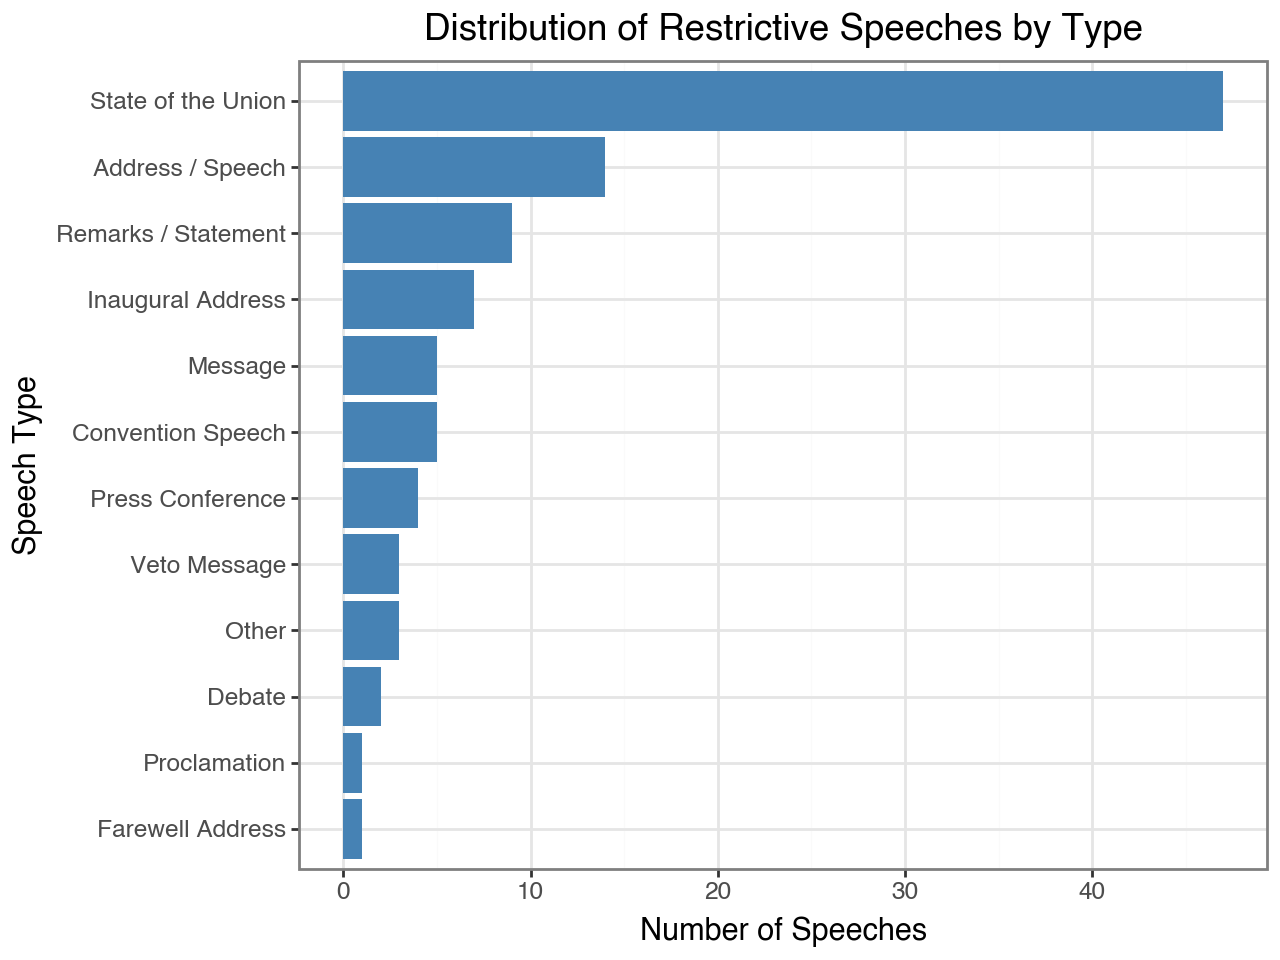

In [121]:
(
    ggplot(data[data['llm_label'] == 'restrictive']['speech_type']
        .value_counts()
        .rename_axis('speech_type')
        .reset_index(name='count'),
        aes(x='reorder(speech_type, count)', y='count')) + 
        geom_col(fill='steelblue') + 
        coord_flip() + 
        labs(
        title='Distribution of Restrictive Speeches by Type',
        x='Speech Type',
        y='Number of Speeches') + 
    theme_bw()
)

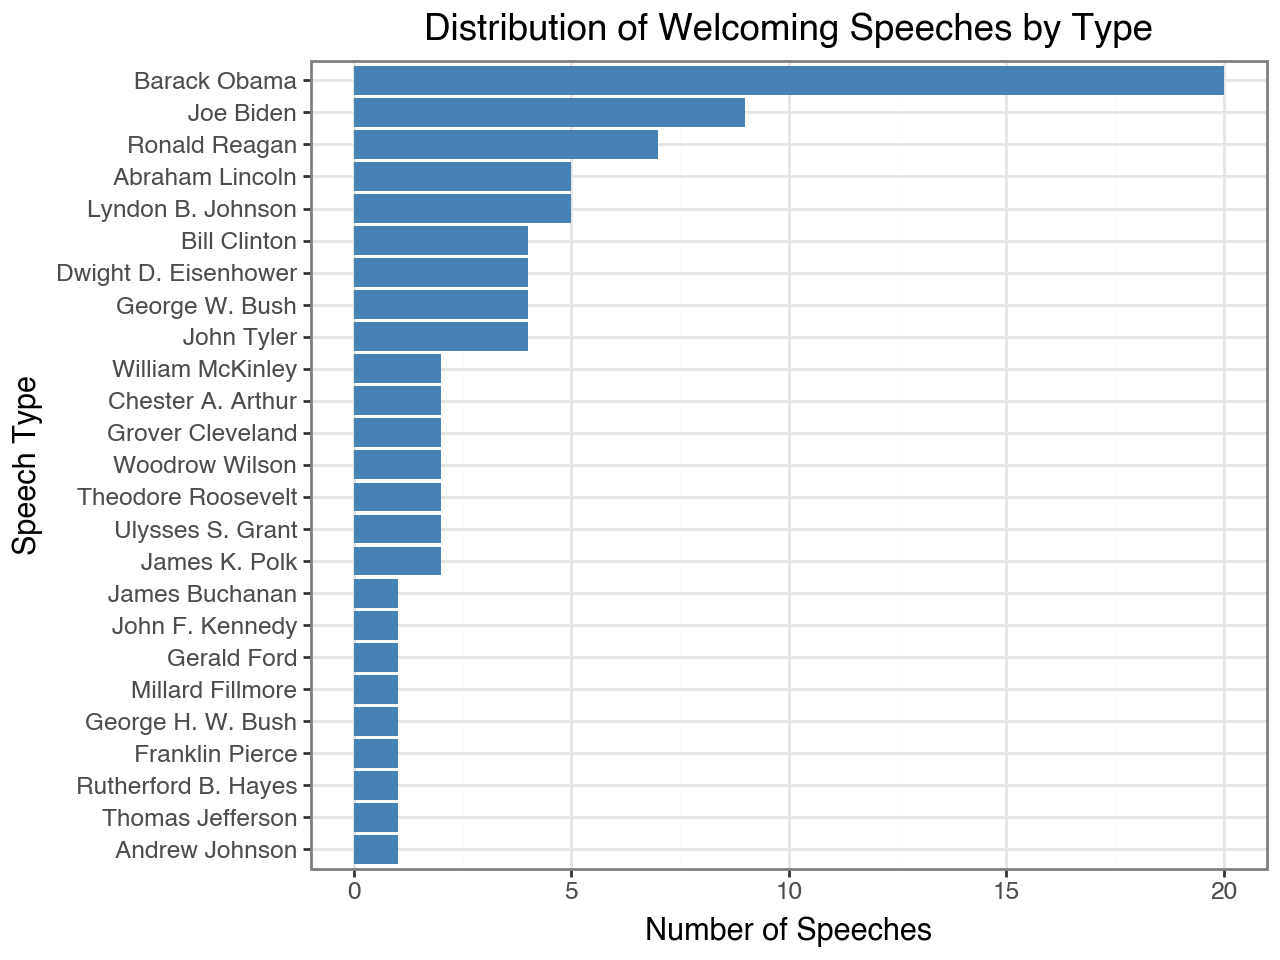

In [122]:
(
    ggplot(data[data['llm_label'] == 'welcoming']['president']
        .value_counts()
        .rename_axis('president')
        .reset_index(name='count'),
        aes(x='reorder(president, count)', y='count')) + 
        geom_col(fill='steelblue') + 
        coord_flip() + 
        labs(
        title='Distribution of Welcoming Speeches by Type',
        x='Speech Type',
        y='Number of Speeches') + 
    theme_bw()
)

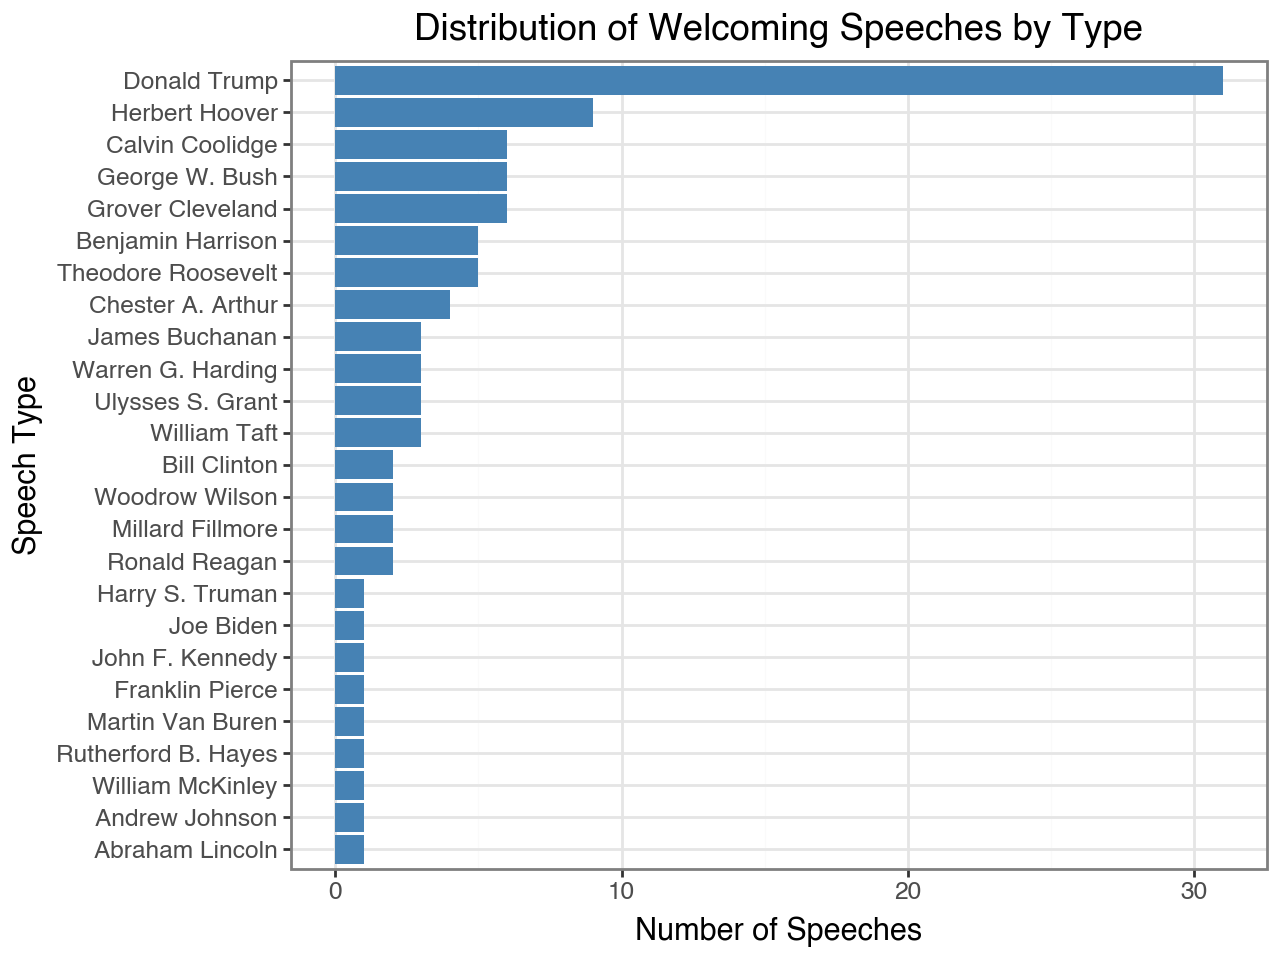

In [123]:
(
    ggplot(data[data['llm_label'] == 'restrictive']['president']
        .value_counts()
        .rename_axis('president')
        .reset_index(name='count'),
        aes(x='reorder(president, count)', y='count')) + 
        geom_col(fill='steelblue') + 
        coord_flip() + 
        labs(
        title='Distribution of Welcoming Speeches by Type',
        x='Speech Type',
        y='Number of Speeches') + 
    theme_bw()
)

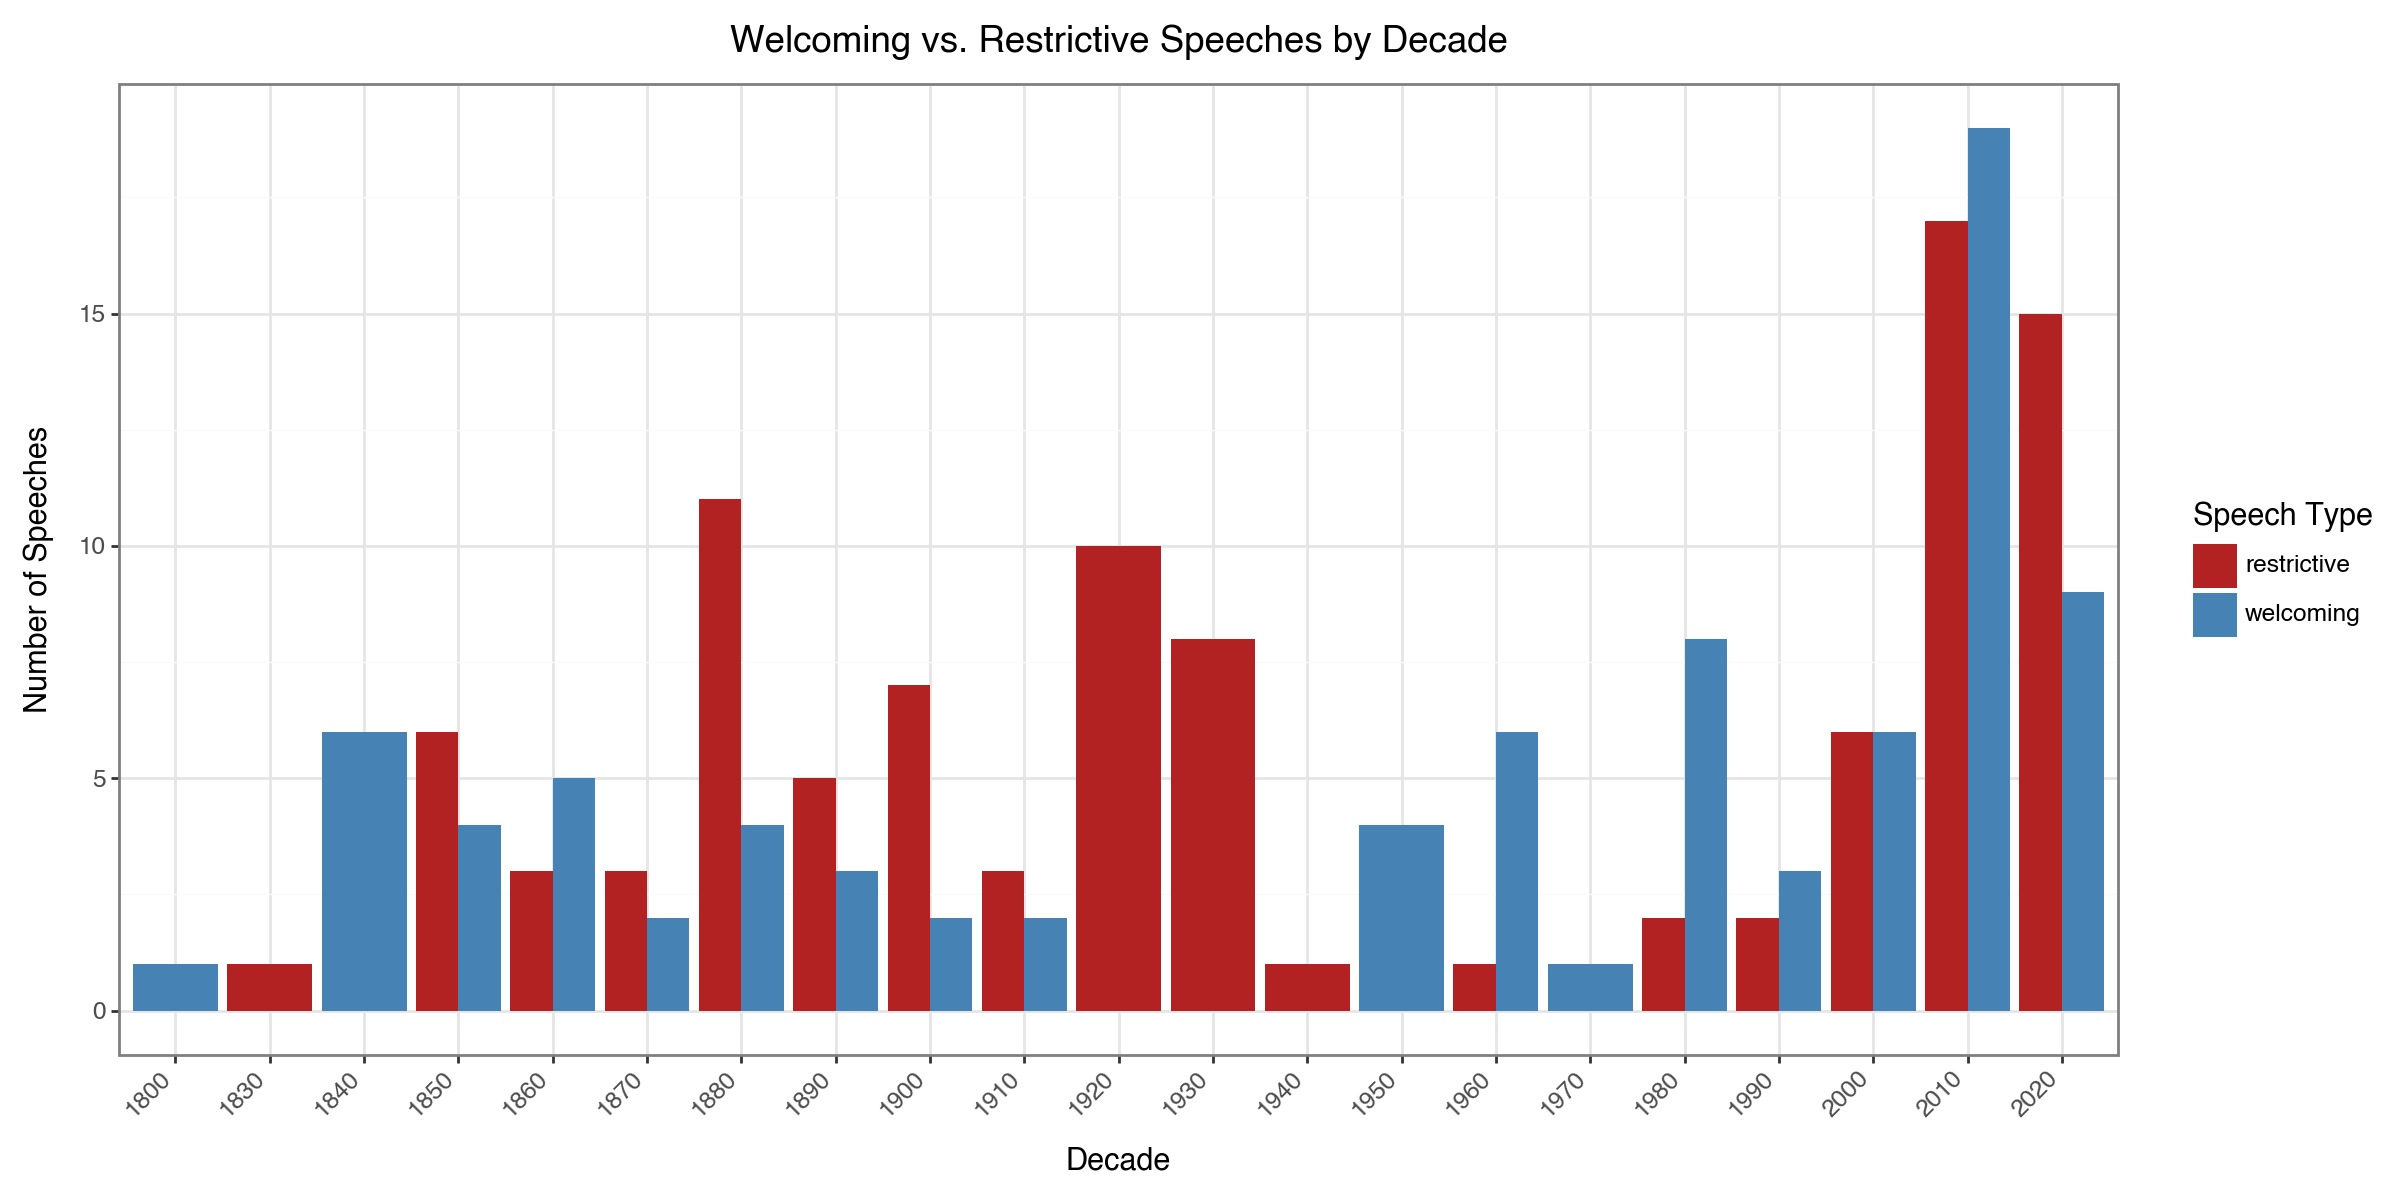

In [151]:
(
    ggplot(data.loc[data['llm_label'].isin(['welcoming', 'restrictive'])]
        .assign(decade=lambda x: x['year'] // 10 * 10)
        .groupby(['decade', 'llm_label'])
        .size()
        .reset_index(name='count'),
        aes(x='factor(decade)', y='count', fill='llm_label')) + 
    geom_col(position='dodge') + 
    labs(title='Welcoming vs. Restrictive Speeches by Decade',
        x='Decade',
        y='Number of Speeches',
        fill='Speech Type') + 
    scale_fill_manual(values={'welcoming': 'steelblue', 'restrictive': 'firebrick'}) + 
    theme_bw() + 
    theme(
        figure_size=(12, 6),
        axis_text_x=element_text(rotation=45, ha='right')
    )
)

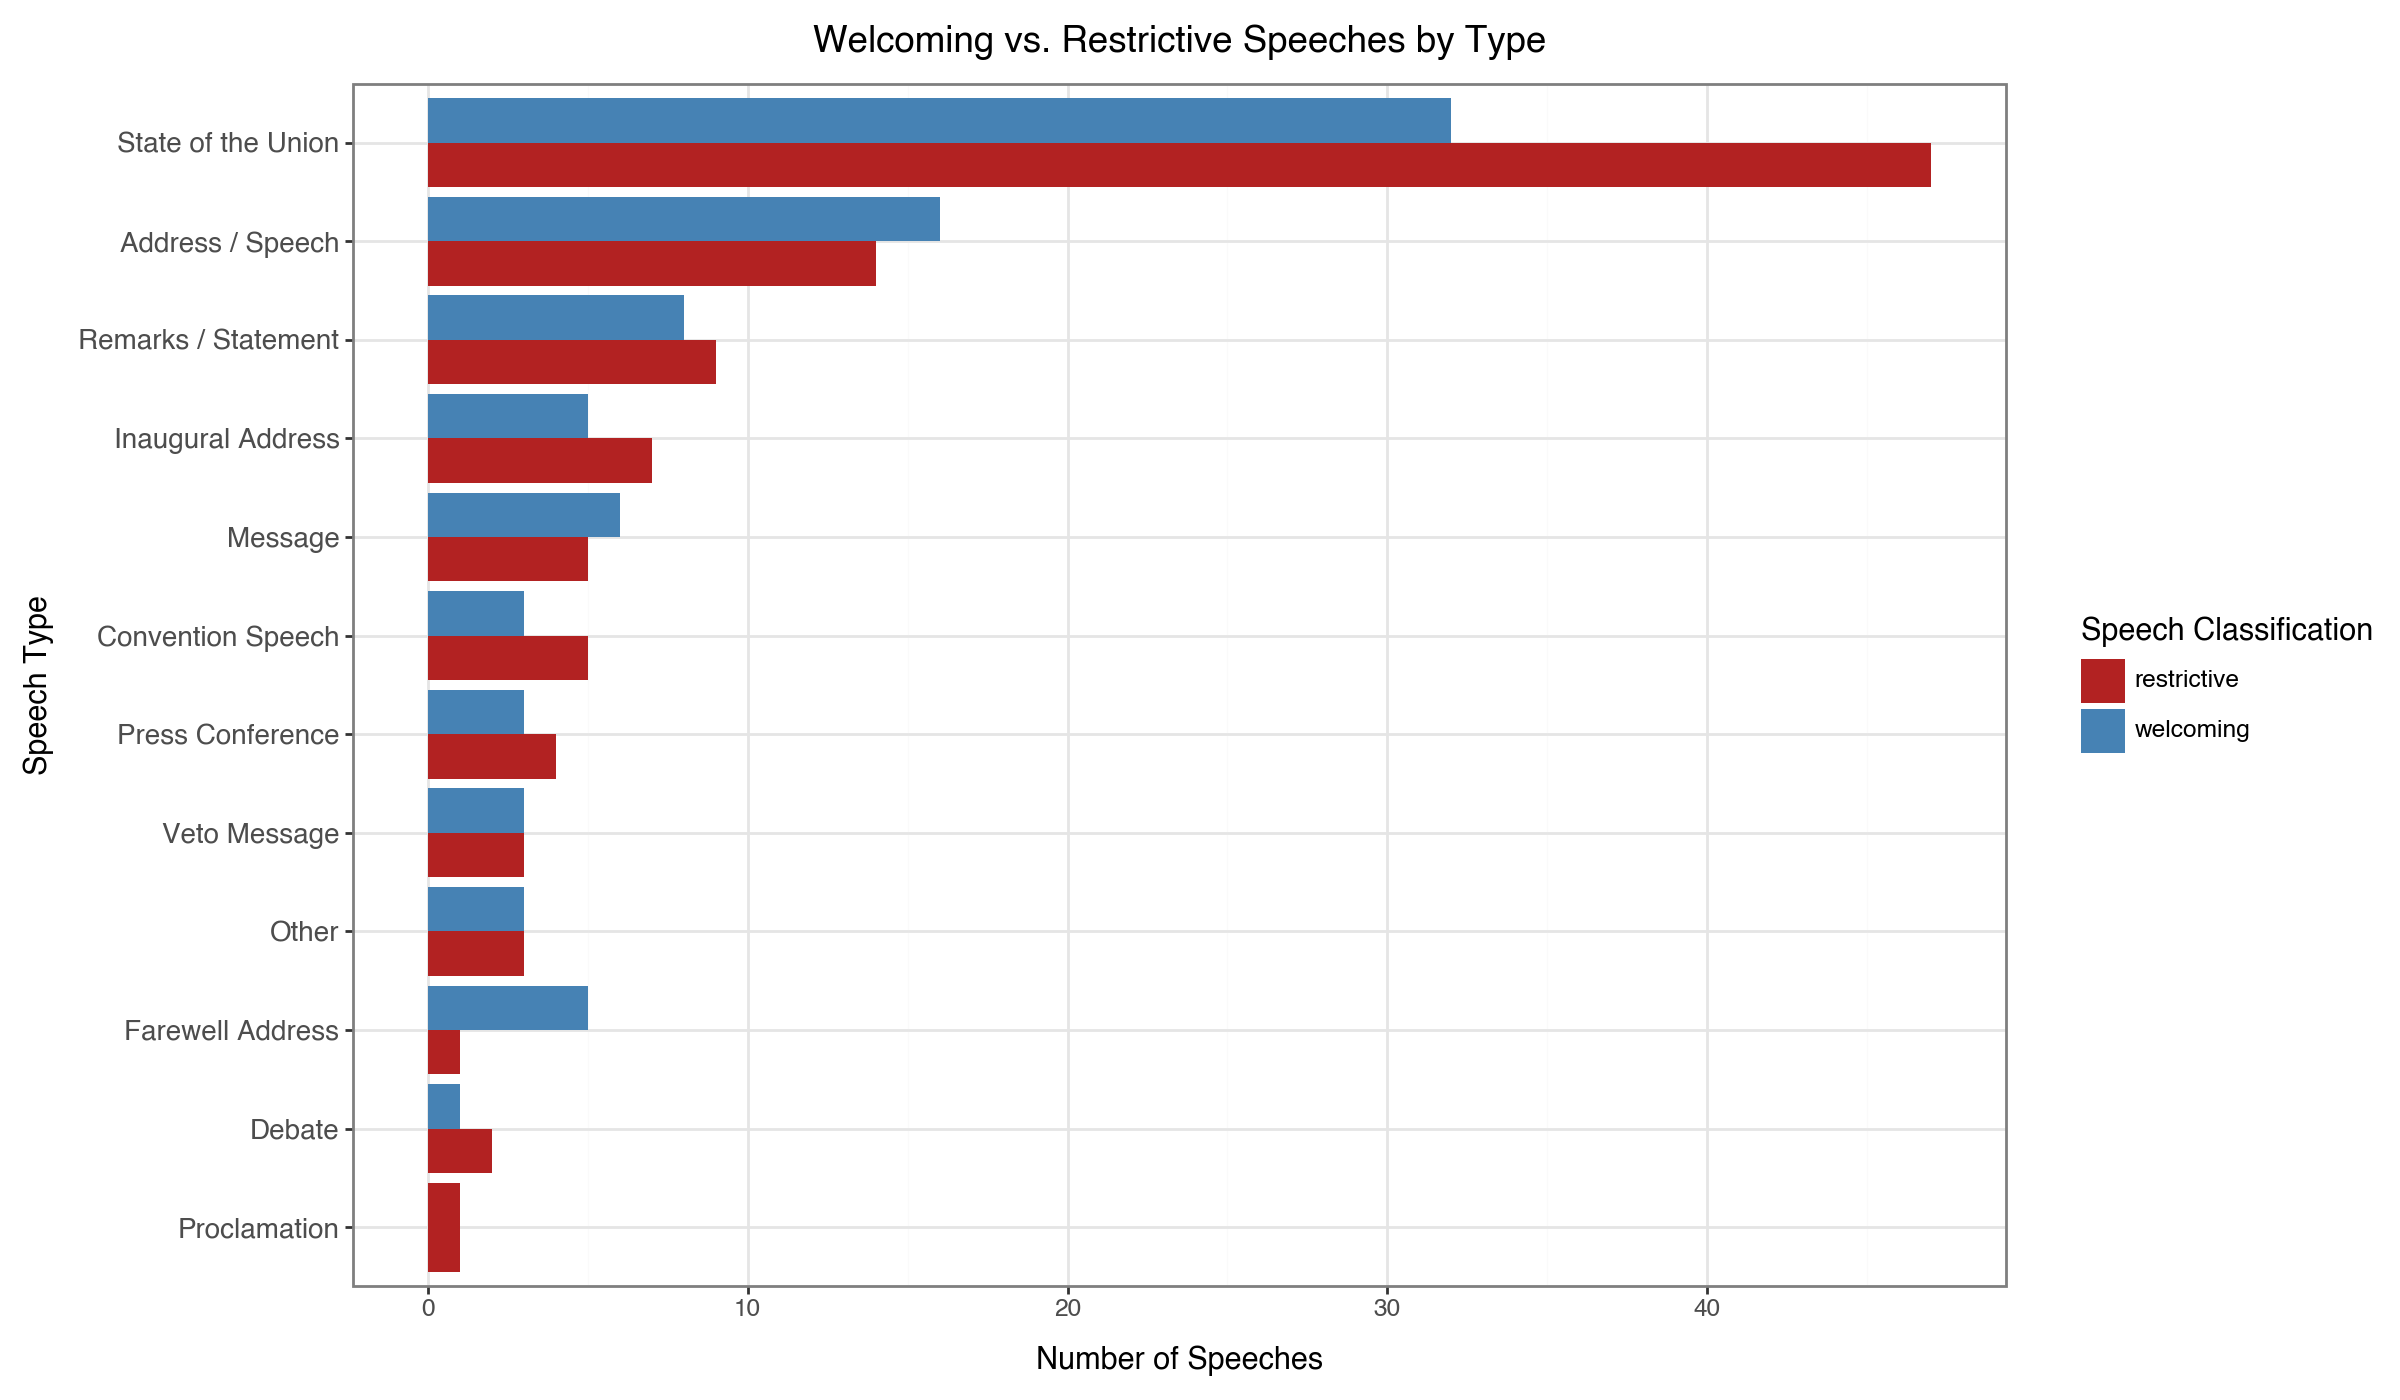

In [150]:
(
    ggplot(data.loc[data['llm_label'].isin(['welcoming', 'restrictive'])]
        .groupby(['speech_type', 'llm_label'])
        .size()
        .reset_index(name='count'),
        aes(x='reorder(speech_type, count)', y='count', fill='llm_label')) + 
    geom_col(position='dodge') + 
    coord_flip() + 
    labs(title='Welcoming vs. Restrictive Speeches by Type',
        x='Speech Type',
        y='Number of Speeches',
        fill='Speech Classification') + 
    scale_fill_manual(
        values={'welcoming': 'steelblue', 'restrictive': 'firebrick'}) + 
    theme_bw() + 
    theme(figure_size=(12, 7),
        axis_text_y=element_text(size=10)
    )
)